# T4.4 — Rotinas de aumento de dados

Aplica transformações que simulam variações de captura em campo (luz, balanço de branco, ângulo, tremor e ruído do sensor) às imagens de **treino**. A lógica está em [`src/aumento.py`](../src/aumento.py) e usa a saída de `preparar_imagem` da [T4.1](../src/preprocessamento.py). As faixas de preenchimento sintético permanecem no cinza neutro original; somente o conteúdo fotografado recebe as transformações.

**Entrada:** o manifesto da T4.2 (`assets/data/particionamento_T4_2/manifesto_provisorio.csv`).

> **Caminho da base:** ajuste `RAIZ_IMAGENS` para a pasta que contém `dataset/`, `Soja/` e `Milho/`.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "assets/data/particionamento_T4_2/manifesto_provisorio.csv").exists()
)
sys.path.insert(0, str(ROOT / "src"))
from aumento import PROBABILIDADE, aplicar_aumento
from preprocessamento import TAMANHO_ENTRADA, preparar_imagem

# Pasta que contém dataset/, Soja/ e Milho/. No Colab, por exemplo: Path("/content/drive/MyDrive/...")
RAIZ_IMAGENS = Path("C:/Users/Inteli/OneDrive/Desktop/Agro App")
MANIFESTO = ROOT / "assets/data/particionamento_T4_2/manifesto_provisorio.csv"
SAIDA = ROOT / "assets/data/aumento_T4_4"

manifesto = pd.read_csv(MANIFESTO, encoding="utf-8-sig")
print("Imagens no manifesto:", len(manifesto))

Imagens no manifesto: 3262


In [2]:
# Confere a base antes de processar. Interrompe com a lista do que falta.
prefixos = manifesto["caminho_relativo"].str.split("/").str[0].unique()
faltando = [pref for pref in prefixos if not (RAIZ_IMAGENS / pref).is_dir()]
if faltando:
    raise FileNotFoundError(
        f"RAIZ_IMAGENS = {RAIZ_IMAGENS.resolve()}\n"
        f"Pastas não encontradas nessa raiz: {faltando}\n"
        "Ajuste RAIZ_IMAGENS para a pasta que contém dataset/, Soja/ e Milho/."
    )
print("Base encontrada em:", RAIZ_IMAGENS.resolve())

Base encontrada em: C:\Users\Inteli\OneDrive\Desktop\Agro App


## 1. Inspeção visual

Quatro imagens de treino. Em cada linha, a primeira coluna é a entrada original (saída de `preparar_imagem`) e as demais são três variações sorteadas com semente fixa.

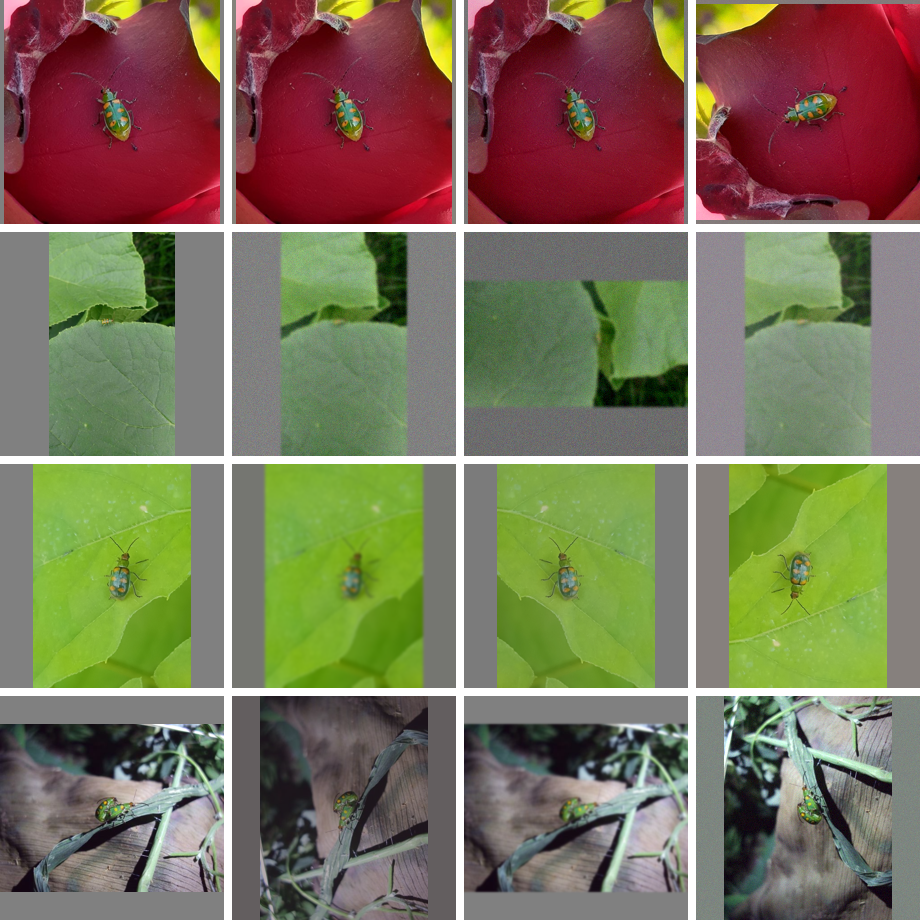

In [3]:
treino = manifesto[manifesto["particao"] == "treino"]
amostra = treino.sample(4, random_state=42)
rng = np.random.default_rng(42)

colunas = 4
grade = Image.new("RGB", (TAMANHO_ENTRADA * colunas + 3 * 8, TAMANHO_ENTRADA * len(amostra) + 8 * (len(amostra) - 1)), (255, 255, 255))
for i, linha in enumerate(amostra.itertuples(index=False)):
    entrada = preparar_imagem(RAIZ_IMAGENS / linha.caminho_relativo)
    variacoes = [entrada] + [aplicar_aumento(entrada, "treino", rng) for _ in range(colunas - 1)]
    for j, imagem in enumerate(variacoes):
        quadro = Image.fromarray((imagem * 255).round().astype(np.uint8))
        grade.paste(quadro, (j * (TAMANHO_ENTRADA + 8), i * (TAMANHO_ENTRADA + 8)))
display(grade)

## 2. Conferência de partição

O aumento deve ser recusado para validação e teste. Aqui todas as linhas do manifesto são testadas: as de treino devem ser aceitas e as demais, recusadas.

In [4]:
aceitas = 0
recusadas = 0
for linha in manifesto.itertuples(index=False):
    try:
        aplicar_aumento(np.zeros((TAMANHO_ENTRADA, TAMANHO_ENTRADA, 3), dtype=np.float32), linha.particao, rng)
    except ValueError:
        recusadas += 1
    else:
        aceitas += 1

print("Imagens de treino aceitas:", aceitas)
print("Imagens de validação e teste recusadas:", recusadas)
assert aceitas == (manifesto["particao"] == "treino").sum()
assert recusadas == len(manifesto) - aceitas

Imagens de treino aceitas: 2287
Imagens de validação e teste recusadas: 975


## 3. Exportação

Grava os parâmetros usados, para que o treinamento possa ser reproduzido.

In [5]:
SAIDA.mkdir(parents=True, exist_ok=True)
(SAIDA / "parametros.json").write_text(
    json.dumps({
        "probabilidade_por_transformacao": PROBABILIDADE,
        "transformacoes": {
            "brilho_contraste": {"contraste": [0.8, 1.2], "brilho": [0.75, 1.25]},
            "balanco_de_branco": {"ganho_por_canal": [0.95, 1.05]},
            "angulo": {"rotacao_graus": [0, 90, 180, 270], "espelhamento_horizontal": 0.5},
            "desfoque_gaussiano": {"raio_px": [0.5, 1.5]},
            "ruido_gaussiano": {"desvio_padrao": [0.005, 0.03]},
        },
        "aplicado_somente_em": "treino",
        "recorte": "nenhum, para não remover lesões nas bordas",
        "preenchimento_sintetico": "preservado em cinza neutro; transformações aplicadas somente ao conteúdo",
        "tamanho_entrada": TAMANHO_ENTRADA,
    }, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
print("Gravado em:", SAIDA.relative_to(ROOT))

Gravado em: assets\data\aumento_T4_4
